# 04. Correlation Analysis
Analyze relationships among chemical parameters and target water quality scores.

## 1. Setup
Set up analytical libraries and plot formatting.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
DATA_PATH = 'data/Dataset/Parquet/Combined Data/Combined_dataset.parquet'
OUT_DIR = 'data/GeneratedOutput/01.EDA'
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join('..', '..', DATA_PATH)
    OUT_DIR = os.path.join('..', '..', OUT_DIR)
os.makedirs(OUT_DIR, exist_ok=True)
df = pd.read_parquet(DATA_PATH)
chemical_cols = [
    'Ammonia (mg/l)', 'Biochemical Oxygen Demand (mg/l)',
    'Dissolved Oxygen (mg/l)', 'Orthophosphate (mg/l)',
    'pH (ph units)', 'Temperature (cel)', 'Nitrogen (mg/l)', 'Nitrate (mg/l)'
]
df_clean = df[(df['pH (ph units)'].isna() | ((df['pH (ph units)'] >= 3) & (df['pH (ph units)'] <= 12))) &
              (df['Temperature (cel)'].isna() | ((df['Temperature (cel)'] >= 0) & (df['Temperature (cel)'] <= 45))) &
              (df['Dissolved Oxygen (mg/l)'].isna() | ((df['Dissolved Oxygen (mg/l)'] >= 0) & (df['Dissolved Oxygen (mg/l)'] <= 25)))].copy()
print(f"Dataset prepared for correlation analysis: {len(df_clean):,} rows.")

Dataset prepared for correlation analysis: 4,287,502 rows.


## 2. Correlation Heatmaps
Compute and display Pearson and Spearman correlation matrices.

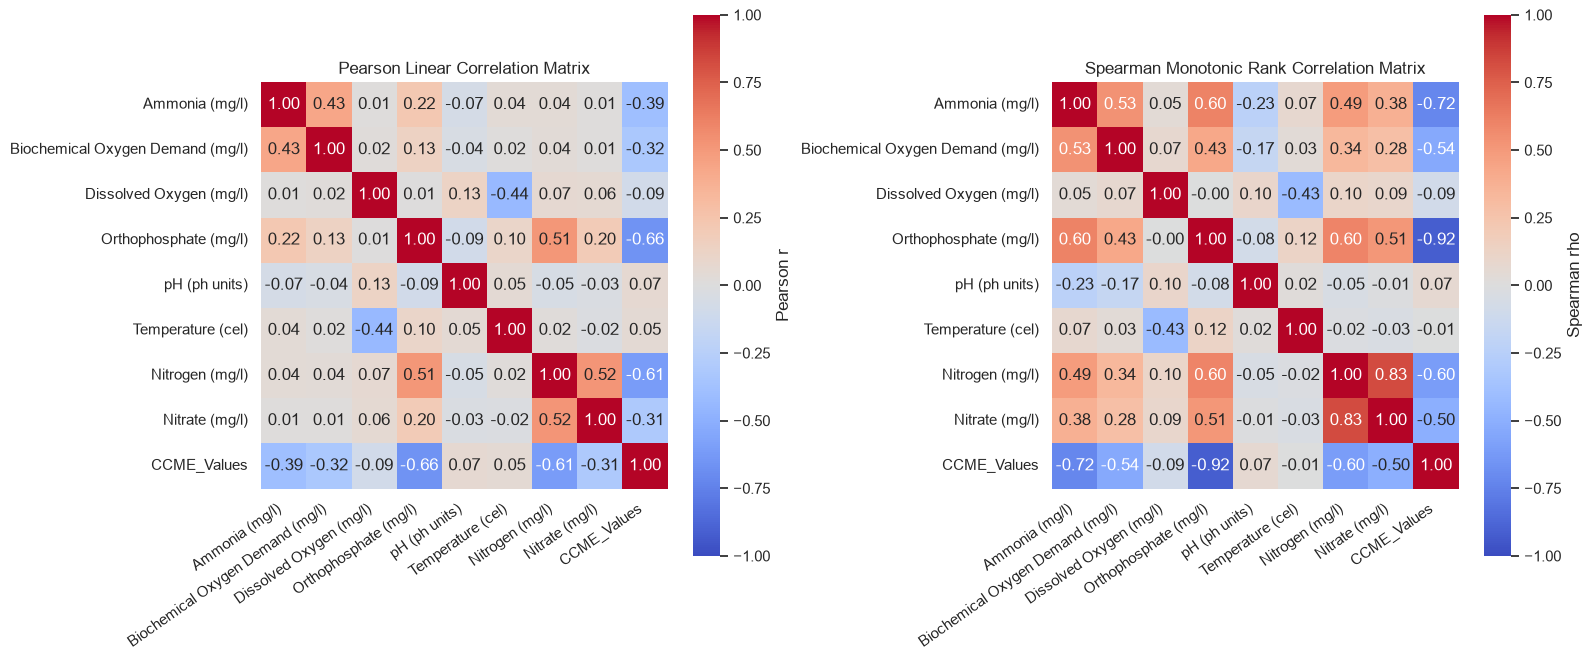

In [2]:
analysis_cols = chemical_cols + ['CCME_Values']
pearson_corr = df_clean[analysis_cols].corr(method='pearson')
spearman_corr = df_clean[analysis_cols].corr(method='spearman')

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

sns.heatmap(pearson_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0], square=True, cbar_kws={'label': 'Pearson r'})
axes[0].set_title('Pearson Linear Correlation Matrix')
axes[0].set_xticklabels(axes[0].get_xticklabels(), rotation=35, ha='right')

sns.heatmap(spearman_corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1], square=True, cbar_kws={'label': 'Spearman rho'})
axes[1].set_title('Spearman Monotonic Rank Correlation Matrix')
axes[1].set_xticklabels(axes[1].get_xticklabels(), rotation=35, ha='right')

plt.tight_layout()
plt.show()

## 3. Nutrient Ratios
Analyze nitrogen-to-phosphorus ratios across samples.

Total Nutrient Measurement Pairs: 2,818,968
Median N:P Mass Ratio:            26.09
Phosphorus-Limited Waters (N:P > 16): 58.4%
Nitrogen-Limited Waters (N:P < 16):   41.5%


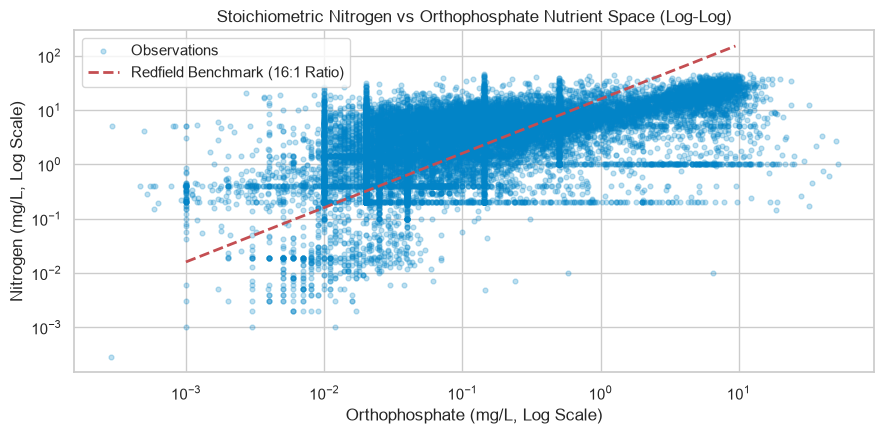

In [3]:
np_df = df_clean.dropna(subset=['Nitrogen (mg/l)', 'Orthophosphate (mg/l)']).copy()
np_df = np_df[(np_df['Nitrogen (mg/l)'] > 0) & (np_df['Orthophosphate (mg/l)'] > 0)]
np_df['NP_Ratio'] = np_df['Nitrogen (mg/l)'] / np_df['Orthophosphate (mg/l)']

p_limited = (np_df['NP_Ratio'] > 16).mean() * 100
n_limited = (np_df['NP_Ratio'] < 16).mean() * 100

print(f"Total Nutrient Measurement Pairs: {len(np_df):,}")
print(f"Median N:P Mass Ratio:            {np_df['NP_Ratio'].median():.2f}")
print(f"Phosphorus-Limited Waters (N:P > 16): {p_limited:.1f}%")
print(f"Nitrogen-Limited Waters (N:P < 16):   {n_limited:.1f}%")

plt.figure(figsize=(9, 4.5))
sample_np = np_df.sample(25000, random_state=42)
plt.scatter(sample_np['Orthophosphate (mg/l)'], sample_np['Nitrogen (mg/l)'], alpha=0.25, s=12, c='#0284c7', label='Observations')
p_vals = np.linspace(0.001, sample_np['Orthophosphate (mg/l)'].quantile(0.99), 100)
plt.plot(p_vals, p_vals * 16, 'r--', lw=2, label='Redfield Benchmark (16:1 Ratio)')

plt.xscale('log')
plt.yscale('log')
plt.title('Stoichiometric Nitrogen vs Orthophosphate Nutrient Space (Log-Log)')
plt.xlabel('Orthophosphate (mg/L, Log Scale)')
plt.ylabel('Nitrogen (mg/L, Log Scale)')
plt.legend()
plt.tight_layout()
plt.show()

## 4. Oxygen Demand vs Deficit
Analyze relationship between biological oxygen demand and dissolved oxygen deficit.

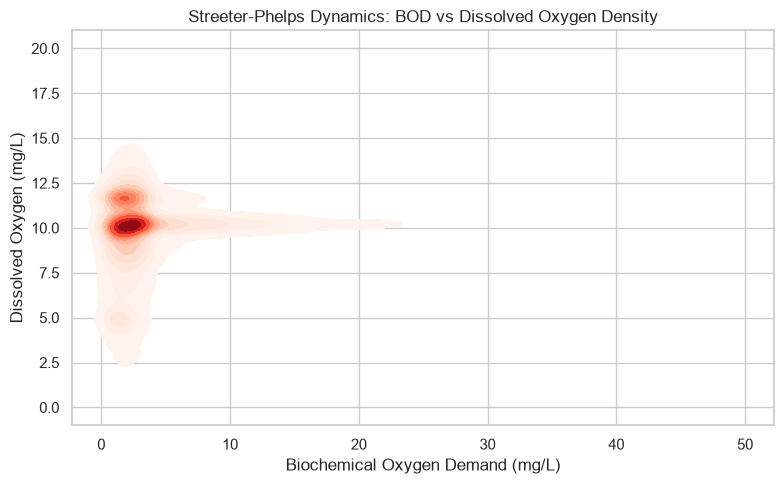

In [4]:
bod_do = df_clean.dropna(subset=['Biochemical Oxygen Demand (mg/l)', 'Dissolved Oxygen (mg/l)']).copy()
sample_bod = bod_do[(bod_do['Biochemical Oxygen Demand (mg/l)'] <= 50) & 
                    (bod_do['Dissolved Oxygen (mg/l)'] <= 20)].sample(30000, random_state=42)

plt.figure(figsize=(8, 5))
sns.kdeplot(data=sample_bod, x='Biochemical Oxygen Demand (mg/l)', y='Dissolved Oxygen (mg/l)', cmap='Reds', fill=True, levels=12, thresh=0.05)
plt.title('Streeter-Phelps Dynamics: BOD vs Dissolved Oxygen Density')
plt.xlabel('Biochemical Oxygen Demand (mg/L)')
plt.ylabel('Dissolved Oxygen (mg/L)')
plt.tight_layout()
plt.show()

## 5. Parameters Across WQI Classes
Compare parameter distributions across water quality grades.

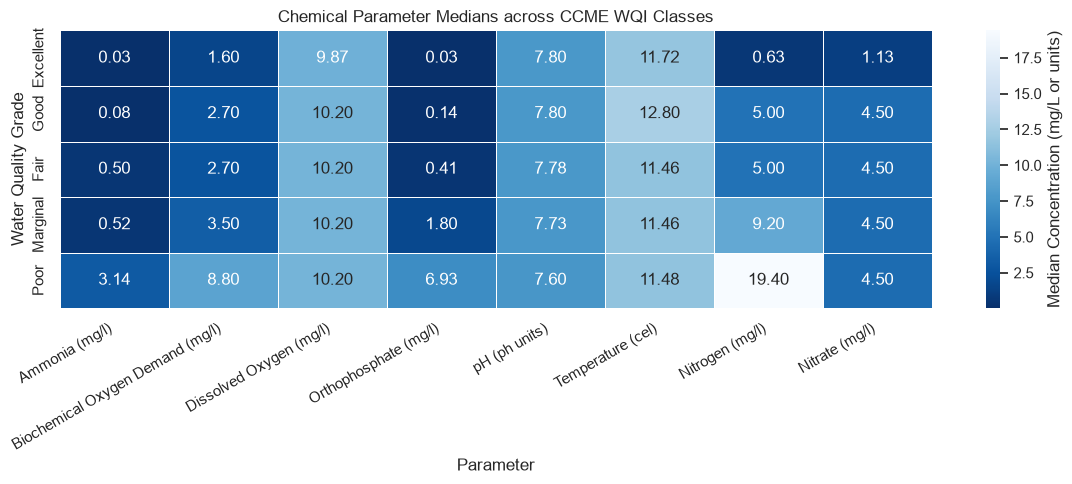

,Ammonia (mg/l),Biochemical Oxygen Demand (mg/l),Dissolved Oxygen (mg/l),Orthophosphate (mg/l),pH (ph units),Temperature (cel),Nitrogen (mg/l),Nitrate (mg/l)
CCME_WQI,,,,,,,,
Excellent,0.030,1.6,9.87,0.027,7.80,11.72,0.629,1.13
Good,0.078,2.7,10.20,0.144,7.80,12.80,5.000,4.50
Fair,0.500,2.7,10.20,0.410,7.78,11.46,5.000,4.50
Marginal,0.520,3.5,10.20,1.800,7.73,11.46,9.200,4.50
Poor,3.140,8.8,10.20,6.930,7.60,11.48,19.400,4.50


In [5]:
order = ['Excellent', 'Good', 'Fair', 'Marginal', 'Poor']
median_profiles = df_clean.groupby('CCME_WQI')[chemical_cols].median().reindex(order)

plt.figure(figsize=(12, 5))
sns.heatmap(median_profiles, annot=True, fmt='.2f', cmap='Blues_r', cbar_kws={'label': 'Median Concentration (mg/L or units)'}, linewidths=0.5)
plt.title('Chemical Parameter Medians across CCME WQI Classes')
plt.xlabel('Parameter')
plt.ylabel('Water Quality Grade')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

median_profiles

## 6. Export Correlations
Save correlation matrices and feature relationships to parquet.

In [6]:
out_path = os.path.join(OUT_DIR, '04_feature_correlations.parquet')
spearman_corr.reset_index().to_parquet(out_path, index=False, compression='snappy')
print(f"Exported Feature Correlation Matrix to: {out_path} ({os.path.getsize(out_path)} bytes)")

Exported Feature Correlation Matrix to: data/GeneratedOutput/01.EDA/04_feature_correlations.parquet (7789 bytes)
